# Swaths — an EMIT granule and TROPOMI averaging kernels on `GeoSwath`

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/geotoolz/blob/main/docs/array/notebooks/swath_averaging_kernels.ipynb)

Imaging spectrometers and trace-gas sounders deliver their data in sensor
geometry: rows along track, columns across, each pixel with its own
latitude and longitude. Orthorectifying first would resample the very
radiances a retrieval needs. `geoarray.GeoSwath` carries them as they
are: the data with named dims, and lat/lon as pytree leaves, so a new
granule of the same shape reuses a compiled program.

The data here are synthetic, shaped like the real products, so the
notebook runs offline.

**What you'll learn:**

1. Build an EMIT-like swath with a `SpectralAxis` of 285 bands and select
   bands by name.
2. Reduce over the swath with pipekit-array's dim-level functions, and see
   why a per-column statistic is a `DimArray`, not a swath.
3. Apply TROPOMI-style averaging kernels on a `GeoSwathProfile` with one
   `KernelOp`, eagerly and under `jit`.
4. Cross to xarray with 2-D lat/lon coordinates and back.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    pipekit = "git+https://github.com/jejjohnson/pipekit"
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            f"pipekit @ {pipekit}#subdirectory=packages/pipekit",
            f"pipekit-array @ {pipekit}#subdirectory=packages/pipekit-array",
            "geotoolz-array[jax,xarray] @ git+https://github.com/jejjohnson/geotoolz@main"
            "#subdirectory=packages/geotoolz-array",
            "matplotlib",
        ],
        check=True,
    )

In [2]:
import jax
import matplotlib.pyplot as plt
import numpy as np
import pipekit_array as pa
from pipekit_array import DimArray, KernelOp

import geoarray
from geoarray import GeoSwath
from geoarray.coords import SpectralAxis, Vertical, VerticalAxis
from geoarray.types import GeoSwathImage, GeoSwathProfile, matches


jax.config.update("jax_enable_x64", True)
rng = np.random.default_rng(0)

## 1. An EMIT-like granule

EMIT measures 285 bands from 381 nm to 2493 nm. A small granule of
64 × 48 pixels, on a track tilted across the Permian Basin: the latitude
and longitude of every pixel are leaves of the carrier.

In [3]:
rows, cols = 64, 48
# along-track and across-track unit steps, in degrees, for a tilted orbit
i, j = np.meshgrid(np.arange(rows), np.arange(cols), indexing="ij")
lat = 31.8 - 0.0006 * i + 0.0002 * j  # (row, col) float64
lon = -103.9 + 0.0002 * i + 0.0006 * j  # (row, col) float64

wavelength = np.linspace(381.0, 2493.0, 285)  # (band,) nm
bands = SpectralAxis(
    names=tuple(f"b{k:03d}" for k in range(285)),
    wavelength_nm=wavelength,
    fwhm_nm=np.full(285, 8.5),
)

# a smooth radiance spectrum with a methane absorption dip near 2300 nm,
# deeper inside a synthetic plume
plume = np.exp(-(((i - 30) / 8.0) ** 2 + ((j - 20) / 5.0) ** 2))  # (row, col)
spectrum = 0.3 + 0.7 * np.exp(-(((wavelength - 900.0) / 700.0) ** 2))  # (band,)
dip = np.exp(-(((wavelength - 2300.0) / 30.0) ** 2))  # (band,)
radiance = (
    spectrum[:, None, None] * (1.0 - 0.3 * dip[:, None, None] * plume)
    + rng.normal(0.0, 0.002, (285, rows, cols))
).astype(np.float32)  # (band, row, col) float32

emit: GeoSwath = GeoSwath(
    radiance,
    lat,
    lon,
    dims=("band", "row", "col"),
    coords=(bands,),
    fill_value=np.nan,
)
emit

GeoSwath(numpy float32 (285, 64, 48), crs=EPSG:4326, fill_value=nan, attrs=(), dims=('band', 'row', 'col'))

It is a `GeoSwathImage`: a swath with dims `band row col`. Bands are
selected by name; the result is still a swath, on the same geolocation.
The names of the bands nearest 2300 nm (in the methane window) and
2150 nm (outside it) come from the `SpectralAxis` wavelengths.

b258 b238


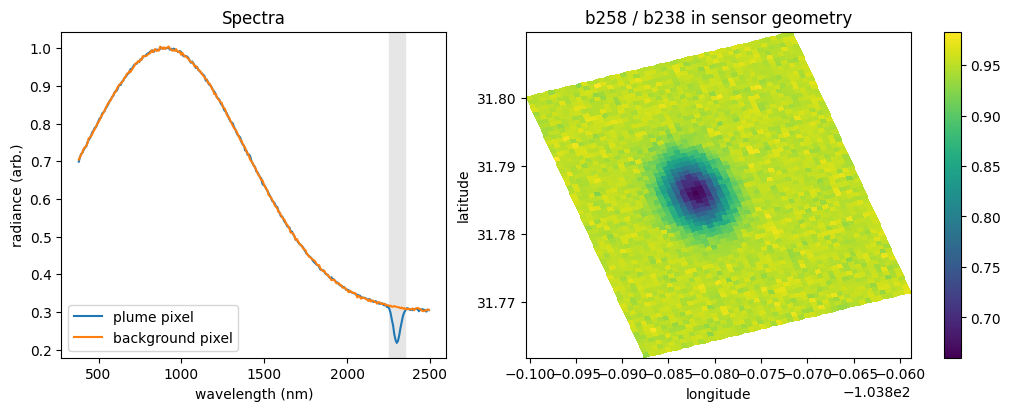

In [4]:
assert matches(emit, GeoSwathImage)
in_name = bands.names[int(np.argmin(np.abs(wavelength - 2300.0)))]
out_name = bands.names[int(np.argmin(np.abs(wavelength - 2150.0)))]
print(in_name, out_name)
in_band = emit.sel(band=in_name)  # inside the methane window
out_band = emit.sel(band=out_name)  # outside it
ratio = pa.combine(lambda a, b: a / b, in_band, out_band)  # (row, col) float32

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].plot(wavelength, radiance[:, 30, 20], label="plume pixel")
axes[0].plot(wavelength, radiance[:, 5, 5], label="background pixel")
axes[0].axvspan(2250, 2350, color="0.9")
axes[0].set(xlabel="wavelength (nm)", ylabel="radiance (arb.)", title="Spectra")
axes[0].legend()
im = axes[1].pcolormesh(lon, lat, np.asarray(ratio.data), shading="auto")
axes[1].set(
    xlabel="longitude",
    ylabel="latitude",
    title=f"{in_name} / {out_name} in sensor geometry",
)
fig.colorbar(im, ax=axes[1])
plt.show()

## 2. Reductions: what stays a swath

The adapter keeps the geolocation while it still describes the result. A
mean over `band` is a swath; a mean over `row` (one value per column, a
classic destriping statistic) has no geolocation left, so it is a plain
`DimArray` with the band labels.

In [5]:
brightness = geoarray.reduce(emit, "mean", "band")  # (row, col): a GeoSwath
column_mean = pa.reduce(emit, "mean", "row")  # (band, col): a DimArray
print(type(brightness).__name__, brightness.dims)
print(type(column_mean).__name__, column_mean.dims)
assert isinstance(column_mean, DimArray)

GeoSwath ('row', 'col')
DimArray ('band', 'col')


## 3. TROPOMI averaging kernels

A trace-gas retrieval reports, per pixel, an averaging kernel A on its
retrieval layers and the prior profile x_a. To compare a model profile x
with the retrieved column, apply the kernel:

$$\hat{c} = c_a + \sum_k A_k \, (x_k - x_{a,k})$$

TROPOMI's CH₄ product has 12 layers in pressure. The kernels and priors
are `GeoSwathProfile`s: swaths with a `level` dim and a `VerticalAxis`.

In [6]:
pressure = Vertical(kind="pressure", units="hPa", positive="down")
layers = VerticalAxis(values=np.linspace(1000.0, 100.0, 12), vertical=pressure)
nr, nc = 40, 30
ti, tj = np.meshgrid(np.arange(nr), np.arange(nc), indexing="ij")
t_lat = 31.5 + 0.06 * ti  # (row, col)
t_lon = -104.5 + 0.07 * tj  # (row, col)

# kernels peaking in the lower troposphere, varying with the scene
height = np.linspace(0.0, 1.0, 12)  # (level,)
ak = np.exp(-((height[:, None, None] - 0.2) ** 2) / 0.1) * (
    0.9 + 0.1 * rng.random((1, nr, nc))
)  # (level, row, col)
prior = np.full((12, nr, nc), 1850.0)  # (level, row, col) ppb
truth = prior + 60.0 * np.exp(-(((ti - 20) / 6.0) ** 2 + ((tj - 15) / 6.0) ** 2))[None]

kernels: GeoSwath = GeoSwath(
    ak, t_lat, t_lon, dims=("level", "row", "col"), coords=(layers,)
)
priors = kernels.with_data(prior)
model = kernels.with_data(truth)
assert matches(kernels, GeoSwathProfile)

One L1 kernel, written on plain arrays with the layer axis last, wrapped
once as a `KernelOp`. The carriers must share their geolocation exactly;
the dispatch checks it and never aligns.

In [7]:
def apply_kernel(a: np.ndarray, x: np.ndarray, xa: np.ndarray, *, c_a: float) -> np.ndarray:
    # ĉ = c_a + Σ_k A_k (x_k − x_a,k), over the last (layer) axis
    return c_a + (a * (x - xa)).sum(-1) / a.shape[-1]


smoothed = KernelOp(
    apply_kernel,
    "(l),(l),(l)->()",
    core={"l": "level"},
    c_a=1850.0,
)
column = smoothed(kernels, model, priors)  # (row, col): a GeoSwath
print(type(column).__name__, column.dims)

GeoSwath ('row', 'col')


The same `KernelOp` runs on JAX carriers under `jit`. A second granule
with the same shape and new lat/lon reuses the compiled program: the
geolocation is a leaf, not part of the cache key.

traces: 1


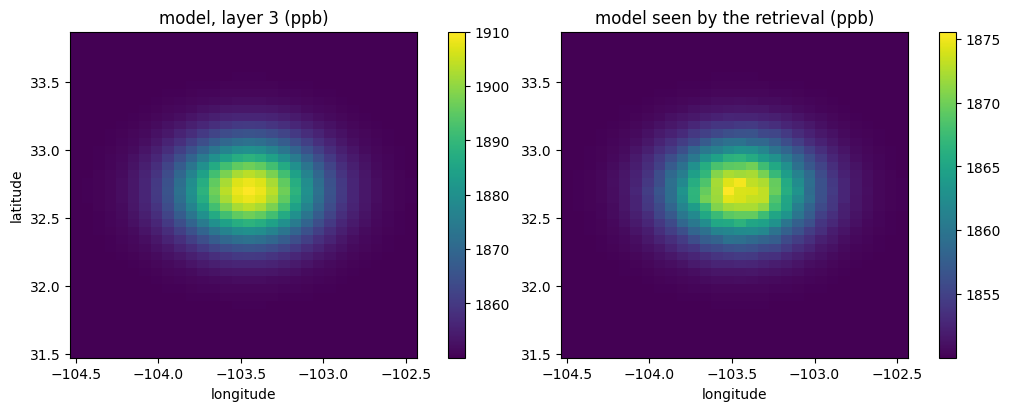

In [8]:
traces = 0


def run(a: GeoSwath, x: GeoSwath, xa: GeoSwath) -> GeoSwath:
    global traces
    traces += 1
    return smoothed(a, x, xa)


fast = jax.jit(run)
on_jax = [c.to_jax() for c in (kernels, model, priors)]
first = fast(*on_jax)
moved = [
    GeoSwath(c.data, c.lat + 1.0, c.lon, dims=c.dims, coords=c.coords) for c in on_jax
]
second = fast(*moved)
print("traces:", traces)
np.testing.assert_allclose(np.asarray(first.data), np.asarray(column.data))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
im0 = axes[0].pcolormesh(t_lon, t_lat, truth[2], shading="auto")
axes[0].set(title="model, layer 3 (ppb)", xlabel="longitude", ylabel="latitude")
fig.colorbar(im0, ax=axes[0])
im1 = axes[1].pcolormesh(t_lon, t_lat, np.asarray(first.data), shading="auto")
axes[1].set(title="model seen by the retrieval (ppb)", xlabel="longitude")
fig.colorbar(im1, ax=axes[1])
plt.show()

## 4. Crossing to xarray

`to_xarray()` writes the swath as a `DataArray` with 2-D `lat` / `lon`
auxiliary coordinates and a CF `spatial_ref`, and `from_xarray()` reads it
back exactly. The level coordinate carries its CF `units` and `positive`.

In [9]:
da = kernels.to_xarray()
print(da.coords["lat"].dims, da.coords["level"].attrs)
assert GeoSwath.from_xarray(da).identical(kernels)
da

('row', 'col') {'units': 'hPa', 'positive': 'down', 'vertical_kind': 'pressure', 'standard_name': 'air_pressure'}


<xarray.DataArray (level: 12, row: 40, col: 30)> Size: 115kB
array([[[0.63924873, 0.60977043, 0.63386099, ..., 0.65886371,
         0.66320026, 0.64257709],
        [0.65209758, 0.62625953, 0.60794716, ..., 0.61635942,
         0.64193269, 0.64881002],
        [0.64253275, 0.66516494, 0.62554629, ..., 0.64067055,
         0.64898334, 0.60845617],
        ...,
        [0.61090978, 0.6627445 , 0.60561542, ..., 0.63706492,
         0.61294321, 0.65751016],
        [0.62203503, 0.66156851, 0.61806539, ..., 0.66493777,
         0.61486506, 0.64496061],
        [0.63054826, 0.65628742, 0.64123759, ..., 0.66378015,
         0.66622773, 0.65122754]],

       [[0.84664828, 0.80760597, 0.83951253, ..., 0.87262721,
         0.87837072, 0.85105651],
        [0.86366585, 0.82944483, 0.80519116, ..., 0.81633271,
         0.85020304, 0.85931167],
        [0.85099778, 0.88097282, 0.8285002 , ..., 0.8485314 ,
         0.85954122, 0.8058653 ],
...
        [0.00597062, 0.00647721, 0.00591887, ..., 0.00622624,
         0.00599049, 0.00642606],
        [0.00607935, 0.00646572, 0.00604055, ..., 0.00649865,
         0.00600927, 0.00630341],
        [0.00616255, 0.00641411, 0.00626702, ..., 0.00648734,
         0.00651126, 0.00636465]],

       [[0.00158454, 0.00151147, 0.00157118, ..., 0.00163316,
         0.00164391, 0.00159279],
        [0.00161639, 0.00155234, 0.00150695, ..., 0.0015278 ,
         0.00159119, 0.00160824],
        [0.00159268, 0.00164878, 0.00155057, ..., 0.00158806,
         0.00160867, 0.00150821],
        ...,
        [0.00151429, 0.00164278, 0.00150117, ..., 0.00157913,
         0.00151933, 0.0016298 ],
        [0.00154187, 0.00163986, 0.00153203, ..., 0.00164822,
         0.0015241 , 0.0015987 ],
        [0.00156297, 0.00162677, 0.00158947, ..., 0.00164535,
         0.00165141, 0.00161423]]], shape=(12, 40, 30))
Coordinates:
  * level        (level) float64 96B 1e+03 918.2 836.4 ... 263.6 181.8 100.0
    lat          (row, col) float64 10kB 31.5 31.5 31.5 ... 33.84 33.84 33.84
    lon          (row, col) float64 10kB -104.5 -104.4 -104.4 ... -102.5 -102.5
    spatial_ref  int32 4B 0
Dimensions without coordinates: row, col

## Recap

- A swath stays in sensor geometry: data with named dims, lat/lon as
  leaves, coordinates (`SpectralAxis`, `VerticalAxis`) as static labels.
- pipekit-array's functions and `KernelOp`s run on it; a result that
  consumed `row` or `col` is a `DimArray`.
- Under `jit`, new geolocation of the same shape costs no recompile.

Next: [When to jit](../how-to/when-to-jit.md) and
[Cross to xarray](../how-to/xarray.md).